# Realistic Human Face Generation using GAN (DCGAN, PyTorch)

**Objective:** train a Generative Adversarial Network that generates realistic synthetic human faces from random noise.

**Pipeline:** CelebA -> crop / resize / normalize -> Generator + Discriminator -> adversarial training -> monitor losses and samples -> compare results over time -> final faces.

## 1. Imports & Setup

In [1]:
import os, random, glob, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.utils as vutils

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. Configuration

In [2]:
# ---- Hyperparameters ----
IMAGE_SIZE = 64        # final image size
CROP_SIZE  = 148       # center crop to focus on the face
NZ         = 100       # latent vector size
NGF        = 64        # generator feature maps
NDF        = 64        # discriminator feature maps
BATCH_SIZE = 128
EPOCHS     = 30
LR         = 2e-4
BETA1      = 0.5
REAL_LABEL = 0.9       # one-sided label smoothing
FAKE_LABEL = 0.0
MAX_IMAGES = None      # e.g. 60000 for a faster run, None = all ~202k images
NUM_WORKERS = 2

SAMPLES_DIR = "samples"
os.makedirs(SAMPLES_DIR, exist_ok=True)

## 3. Load the dataset (CelebA)
Downloads CelebA from Kaggle with `kagglehub`. On Kaggle, you can instead add the dataset
`jessicali9530/celeba-dataset` to the notebook and it will be found automatically.

In [3]:
def find_celeba():
    # Kaggle notebook path
    kaggle_path = "/kaggle/input/celeba-dataset/img_align_celeba/img_align_celeba"
    if os.path.isdir(kaggle_path):
        return kaggle_path
    # Elsewhere (Colab, local): download with kagglehub
    # (needs Kaggle credentials: KAGGLE_USERNAME / KAGGLE_KEY or kaggle.json)
    import kagglehub
    root = kagglehub.dataset_download("jessicali9530/celeba-dataset")
    for dirpath, _, files in os.walk(root):
        if len([f for f in files if f.endswith(".jpg")]) > 1000:
            return dirpath
    raise FileNotFoundError("CelebA images not found")

# If kagglehub is missing:  !pip install -q kagglehub
DATA_DIR = find_celeba()
print("Data dir:", DATA_DIR)

Data dir: /kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba


## 4. Preprocessing: crop -> resize -> normalize to [-1, 1]

In [4]:
transform = T.Compose([
    T.CenterCrop(CROP_SIZE),
    T.Resize(IMAGE_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),                                   # [0, 1]
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),  # [-1, 1] to match tanh output
])

class FaceDataset(Dataset):
    def __init__(self, root, transform, max_images=None):
        self.files = sorted(glob.glob(os.path.join(root, "*.jpg")))
        if max_images:
            self.files = self.files[:max_images]
        self.transform = transform
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        img = Image.open(self.files[i]).convert("RGB")
        return self.transform(img)

dataset = FaceDataset(DATA_DIR, transform, MAX_IMAGES)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
print("Number of images:", len(dataset))

Number of images: 202599


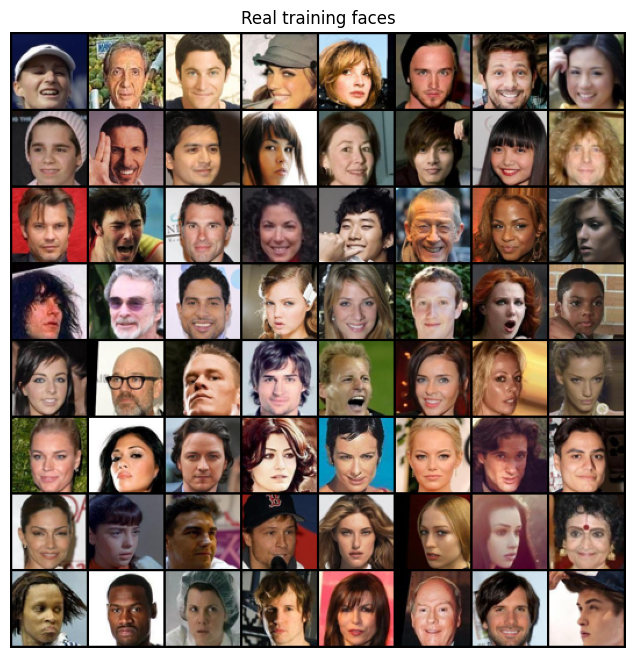

In [5]:
# Visualize a batch of real faces
real_batch = next(iter(dataloader))
plt.figure(figsize=(8, 8))
plt.axis("off"); plt.title("Real training faces")
grid = vutils.make_grid(real_batch[:64], padding=2, normalize=True)
plt.imshow(grid.permute(1, 2, 0)); plt.show()

## 5. Generator
Latent vector (100) -> 4x4x512 -> 8x8x256 -> 16x16x128 -> 32x32x64 -> 64x64x3 (tanh).

In [6]:
class Generator(nn.Module):
    def __init__(self, nz=NZ, ngf=NGF):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf*8, 4, 1, 0, bias=False),     # 4x4
            nn.BatchNorm2d(ngf*8), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*8, ngf*4, 4, 2, 1, bias=False),  # 8x8
            nn.BatchNorm2d(ngf*4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False),  # 16x16
            nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False),    # 32x32
            nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False),        # 64x64
            nn.Tanh(),
        )
    def forward(self, z):
        return self.net(z)

## 6. Discriminator
64x64x3 -> 32 -> 16 -> 8 -> 4 -> probability real/fake (sigmoid). No BatchNorm on the first layer.

In [7]:
class Discriminator(nn.Module):
    def __init__(self, ndf=NDF):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False),                 # 32x32
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False),             # 16x16
            nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf*2, ndf*4, 4, 2, 1, bias=False),           # 8x8
            nn.BatchNorm2d(ndf*4), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf*4, ndf*8, 4, 2, 1, bias=False),           # 4x4
            nn.BatchNorm2d(ndf*8), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf*8, 1, 4, 1, 0, bias=False),               # 1x1
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x).view(-1)

def weights_init(m):
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

netG = Generator().to(device); netG.apply(weights_init)
netD = Discriminator().to(device); netD.apply(weights_init)
print(netG); print(netD)

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)
D

## 7. Loss, optimizers and fixed noise

In [8]:
criterion = nn.BCELoss()
optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))

# Same noise every epoch -> we can compare how the SAME latent vectors evolve
fixed_noise = torch.randn(64, NZ, 1, 1, device=device)

G_losses, D_losses = [], []      # per-epoch averages
D_real_scores, D_fake_scores = [], []
saved_epochs = []

## 8. Training loop (adversarial learning)
Each step:
1. **Discriminator:** real batch (label 0.9) + fake batch (label 0), maximize its ability to tell them apart.
2. **Generator:** generate fakes and try to make the Discriminator say "real" (label 1).

Generated samples from `fixed_noise` are saved after every epoch.

In [9]:
def save_samples(epoch):
    netG.eval()
    with torch.no_grad():
        fake = netG(fixed_noise).cpu()
    netG.train()
    vutils.save_image(fake, f"{SAMPLES_DIR}/epoch_{epoch:03d}.png",
                      nrow=8, padding=2, normalize=True, value_range=(-1, 1))
    saved_epochs.append(epoch)

start = time.time()
for epoch in range(1, EPOCHS + 1):
    g_run = d_run = dr_run = df_run = 0.0
    for i, real in enumerate(dataloader):
        real = real.to(device, non_blocking=True)
        b = real.size(0)

        # ---- (1) Train Discriminator ----
        netD.zero_grad()
        out_real = netD(real)
        loss_real = criterion(out_real, torch.full((b,), REAL_LABEL, device=device))

        noise = torch.randn(b, NZ, 1, 1, device=device)
        fake = netG(noise)
        out_fake = netD(fake.detach())
        loss_fake = criterion(out_fake, torch.full((b,), FAKE_LABEL, device=device))

        lossD = loss_real + loss_fake
        lossD.backward()
        optimizerD.step()

        # ---- (2) Train Generator ----
        netG.zero_grad()
        out = netD(fake)
        lossG = criterion(out, torch.ones(b, device=device))   # want D to say "real"
        lossG.backward()
        optimizerG.step()

        g_run += lossG.item(); d_run += lossD.item()
        dr_run += out_real.mean().item(); df_run += out_fake.mean().item()

    n = len(dataloader)
    G_losses.append(g_run / n); D_losses.append(d_run / n)
    D_real_scores.append(dr_run / n); D_fake_scores.append(df_run / n)
    save_samples(epoch)
    print(f"Epoch [{epoch}/{EPOCHS}]  D loss: {D_losses[-1]:.3f}  G loss: {G_losses[-1]:.3f}  "
          f"D(x): {D_real_scores[-1]:.3f}  D(G(z)): {D_fake_scores[-1]:.3f}  "
          f"time: {(time.time()-start)/60:.1f} min")

    # checkpoint
    torch.save({"G": netG.state_dict(), "D": netD.state_dict(), "epoch": epoch}, "gan_checkpoint.pt")

Epoch [1/30]  D loss: 0.777  G loss: 4.947  D(x): 0.748  D(G(z)): 0.152  time: 50.3 min
Epoch [2/30]  D loss: 0.794  G loss: 3.477  D(x): 0.721  D(G(z)): 0.178  time: 63.1 min
Epoch [3/30]  D loss: 0.842  G loss: 2.786  D(x): 0.692  D(G(z)): 0.207  time: 77.0 min
Epoch [4/30]  D loss: 0.827  G loss: 2.766  D(x): 0.697  D(G(z)): 0.202  time: 91.9 min
Epoch [5/30]  D loss: 0.833  G loss: 2.796  D(x): 0.696  D(G(z)): 0.203  time: 107.7 min
Epoch [6/30]  D loss: 0.804  G loss: 2.835  D(x): 0.705  D(G(z)): 0.194  time: 123.8 min
Epoch [7/30]  D loss: 0.767  G loss: 3.009  D(x): 0.727  D(G(z)): 0.173  time: 140.5 min
Epoch [8/30]  D loss: 0.757  G loss: 3.055  D(x): 0.734  D(G(z)): 0.166  time: 157.4 min
Epoch [9/30]  D loss: 0.684  G loss: 3.286  D(x): 0.761  D(G(z)): 0.138  time: 174.8 min
Epoch [10/30]  D loss: 0.684  G loss: 3.372  D(x): 0.767  D(G(z)): 0.133  time: 192.6 min
Epoch [11/30]  D loss: 0.645  G loss: 3.448  D(x): 0.781  D(G(z)): 0.119  time: 210.4 min
Epoch [12/30]  D loss: 

## 9. Loss curves

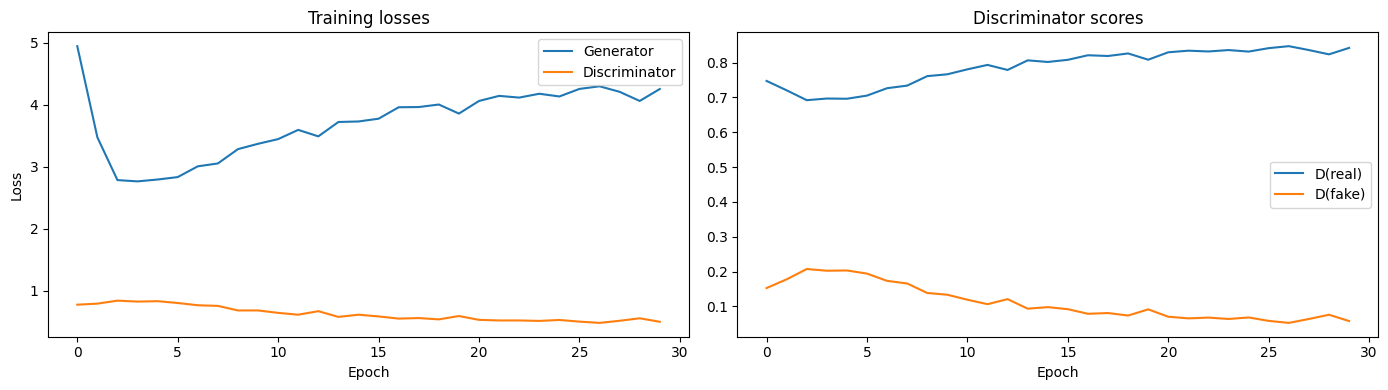

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(G_losses, label="Generator"); ax[0].plot(D_losses, label="Discriminator")
ax[0].set_title("Training losses"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
ax[1].plot(D_real_scores, label="D(real)"); ax[1].plot(D_fake_scores, label="D(fake)")
ax[1].set_title("Discriminator scores"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

## 10. Progress over time (same fixed noise at different epochs)

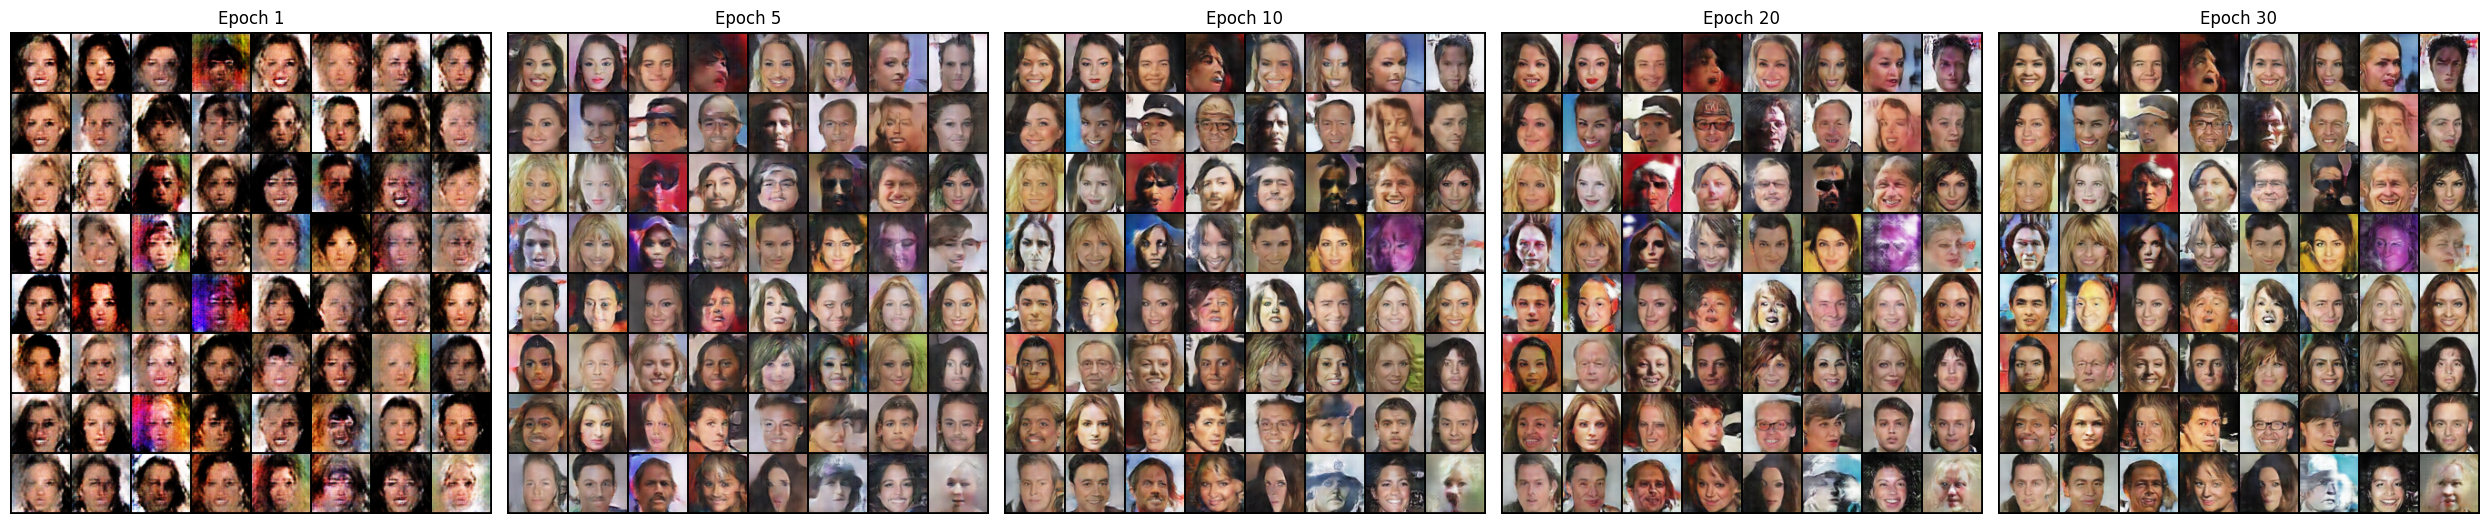

In [11]:
show = sorted(set([1, 5, 10, 20, EPOCHS]))
show = [e for e in show if e <= EPOCHS]
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 5.5))
for ax, e in zip(np.atleast_1d(axes), show):
    ax.imshow(Image.open(f"{SAMPLES_DIR}/epoch_{e:03d}.png")); ax.set_title(f"Epoch {e}"); ax.axis("off")
plt.tight_layout(); plt.savefig("progress_comparison.png", dpi=150); plt.show()

In [12]:
# Optional: GIF of the training evolution
frames = [Image.open(f"{SAMPLES_DIR}/epoch_{e:03d}.png") for e in saved_epochs]
frames[0].save("training_progress.gif", save_all=True, append_images=frames[1:], duration=300, loop=0)
print("Saved training_progress.gif")

Saved training_progress.gif


## 11. Final generated faces

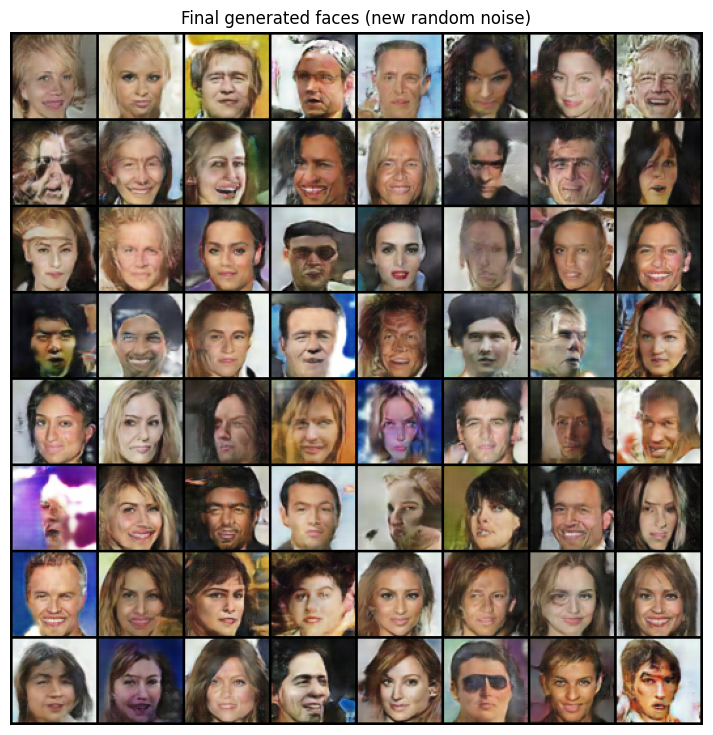

In [13]:
netG.eval()
with torch.no_grad():
    z = torch.randn(64, NZ, 1, 1, device=device)
    final = netG(z).cpu()
plt.figure(figsize=(9, 9)); plt.axis("off"); plt.title("Final generated faces (new random noise)")
plt.imshow(vutils.make_grid(final, nrow=8, padding=2, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.savefig("final_faces.png", dpi=150, bbox_inches="tight"); plt.show()

## 12. Real vs generated (side by side)

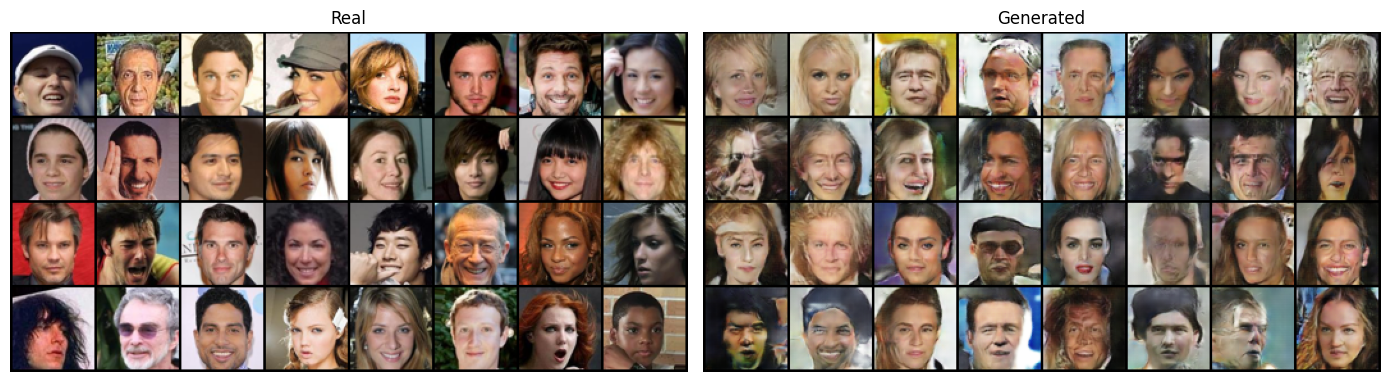

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(vutils.make_grid(real_batch[:32], nrow=8, padding=2, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
ax[0].set_title("Real"); ax[0].axis("off")
ax[1].imshow(vutils.make_grid(final[:32], nrow=8, padding=2, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
ax[1].set_title("Generated"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 13. (Optional) Latent space interpolation

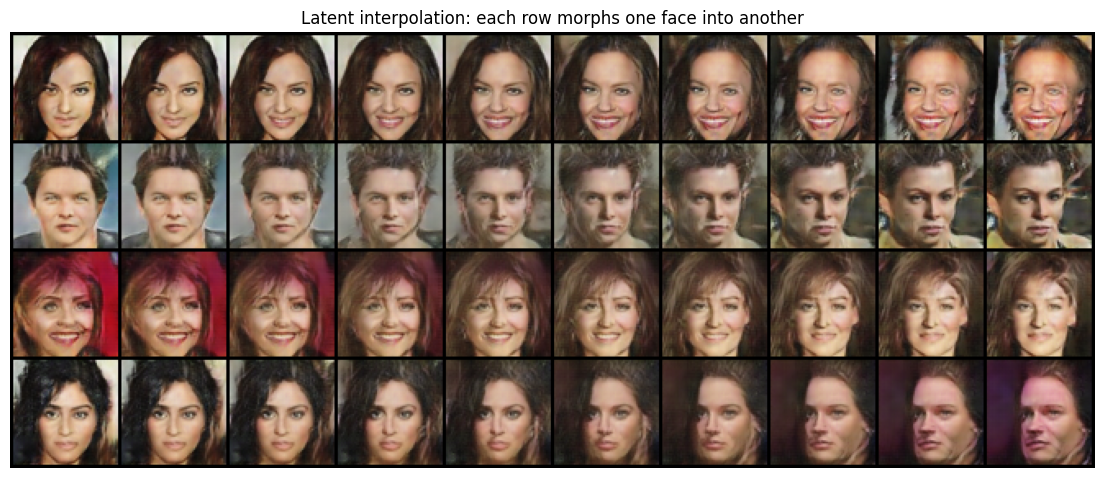

In [15]:
def interpolate(steps=10):
    z1, z2 = torch.randn(1, NZ, 1, 1, device=device), torch.randn(1, NZ, 1, 1, device=device)
    alphas = torch.linspace(0, 1, steps, device=device).view(-1, 1, 1, 1)
    z = (1 - alphas) * z1 + alphas * z2
    with torch.no_grad():
        return netG(z).cpu()

rows = torch.cat([interpolate() for _ in range(4)])
plt.figure(figsize=(14, 6)); plt.axis("off"); plt.title("Latent interpolation: each row morphs one face into another")
plt.imshow(vutils.make_grid(rows, nrow=10, padding=2, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.savefig("interpolation.png", dpi=150, bbox_inches="tight"); plt.show()

## 14. Save the final Generator

In [16]:
torch.save(netG.state_dict(), "generator.pth")
print("Saved generator.pth")

Saved generator.pth


## 15. (Optional) Gradio demo
Run `!pip install -q gradio` first.

In [17]:
# !pip install -q gradio
import gradio as gr

def generate_face(seed):
    g = torch.Generator(device=device).manual_seed(int(seed))
    z = torch.randn(1, NZ, 1, 1, device=device, generator=g)
    with torch.no_grad():
        img = netG(z).cpu()[0]
    img = (img * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    return Image.fromarray((img * 255).astype("uint8")).resize((256, 256), Image.LANCZOS)

demo = gr.Interface(
    fn=generate_face,
    inputs=gr.Slider(0, 9999, value=42, step=1, label="Seed"),
    outputs=gr.Image(label="Generated face"),
    title="Realistic Human Face Generation (DCGAN)",
    description="Generates a synthetic 64x64 face from random noise.",
)
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://6b933709d24431343b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
